# Brain Tumor MRI Classification with Swin Transformer

Fine-tuning an ImageNet-pretrained **Swin-Tiny** (`swin_tiny_patch4_window7_224`, via `timm`) to classify brain MRI slices into **glioma, meningioma, pituitary tumor, and no tumor**.

Pipeline: data loading & augmentation → stage 1: train classifier head → stage 2: fine-tune last two Swin stages → evaluation on the held-out test set → Grad-CAM explainability.

## 1. Data loading & preprocessing
Images are resized to 224×224 and normalized to [-1, 1]. Training uses random horizontal flips and ±10° rotations.

In [2]:
import os
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# --------------------
# CONFIG
# --------------------
DATA_DIR = "data"  # contains Training/ and Testing/ (see README)
IMG_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 4
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Using device:", DEVICE)

# --------------------
# TRANSFORMS
# --------------------
train_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])

test_tfms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5]*3, std=[0.5]*3)
])

# --------------------
# DATASETS
# --------------------
train_ds = datasets.ImageFolder(os.path.join(DATA_DIR, "Training"), transform=train_tfms)
test_ds  = datasets.ImageFolder(os.path.join(DATA_DIR, "Testing"), transform=test_tfms)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=4)
test_loader  = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=4)

print("Classes:", train_ds.classes)
print("Train samples:", len(train_ds))
print("Test samples:", len(test_ds))


Using device: cuda
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Train samples: 5712
Test samples: 1311


## 2. Stage 1: train the classification head
The pretrained backbone is frozen; only the new 4-class head is trained (AdamW, lr 1e-3).

In [ ]:
import timm
import torch.nn as nn
from torch.optim import AdamW
from tqdm import tqdm

# --------------------
# LOAD PRETRAINED SWIN
# --------------------
model = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    num_classes=NUM_CLASSES
).to(DEVICE)

# --------------------
# FREEZE BACKBONE
# --------------------
for name, param in model.named_parameters():
    if "head" not in name:
        param.requires_grad = False

# --------------------
# TRAIN SETUP
# --------------------
criterion = nn.CrossEntropyLoss()
optimizer = AdamW(model.head.parameters(), lr=1e-3)

EPOCHS = 15

# --------------------
# TRAIN LOOP
# --------------------
for epoch in range(EPOCHS):
    model.train()
    correct, total = 0, 0

    for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    acc = 100 * correct / total
    print(f"Epoch {epoch+1}: Train Accuracy = {acc:.2f}%")


## 3. Stage 2: fine-tune the last two Swin stages
`layers.2`, `layers.3` and the head are unfrozen and trained with a lower learning rate (1e-4).

In [3]:
# --------------------
# UNFREEZE LAST STAGES
# --------------------
for name, param in model.named_parameters():
    if "layers.2" in name or "layers.3" in name or "head" in name:
        param.requires_grad = True

# --------------------
# LOWER LR FOR FINE-TUNING
# --------------------
optimizer = AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=1e-4
)

FINE_TUNE_EPOCHS = 10

# --------------------
# FINE-TUNING LOOP
# --------------------
for epoch in range(FINE_TUNE_EPOCHS):
    model.train()
    correct, total = 0, 0

    for imgs, labels in tqdm(train_loader, desc=f"Fine-tune {epoch+1}/{FINE_TUNE_EPOCHS}"):
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        preds = outputs.argmax(1)
        correct += (preds == labels).sum().item()
        total += labels.size(0)

    acc = 100 * correct / total
    print(f"Fine-tune Epoch {epoch+1}: Train Accuracy = {acc:.2f}%")


Fine-tune Epoch 1: Train Accuracy = 91.16%


Fine-tune Epoch 2: Train Accuracy = 96.80%


Fine-tune Epoch 3: Train Accuracy = 97.65%


Fine-tune Epoch 4: Train Accuracy = 97.81%


Fine-tune Epoch 5: Train Accuracy = 98.98%


Fine-tune Epoch 6: Train Accuracy = 98.86%


Fine-tune Epoch 7: Train Accuracy = 98.98%


Fine-tune Epoch 8: Train Accuracy = 98.91%


Fine-tune Epoch 9: Train Accuracy = 98.42%


Fine-tune Epoch 10: Train Accuracy = 98.90%


In [ ]:
os.makedirs("saved_models", exist_ok=True)
torch.save(model.state_dict(), "saved_models/swin_final.pth")

## 4. Evaluation on the held-out test set


✅ FINAL TEST ACCURACY: 99.24%

📊 CLASSIFICATION REPORT

              precision    recall  f1-score   support

      glioma       0.98      1.00      0.99       300
  meningioma       0.99      0.97      0.98       306
     notumor       1.00      1.00      1.00       405
   pituitary       0.99      1.00      0.99       300

    accuracy                           0.99      1311
   macro avg       0.99      0.99      0.99      1311
weighted avg       0.99      0.99      0.99      1311



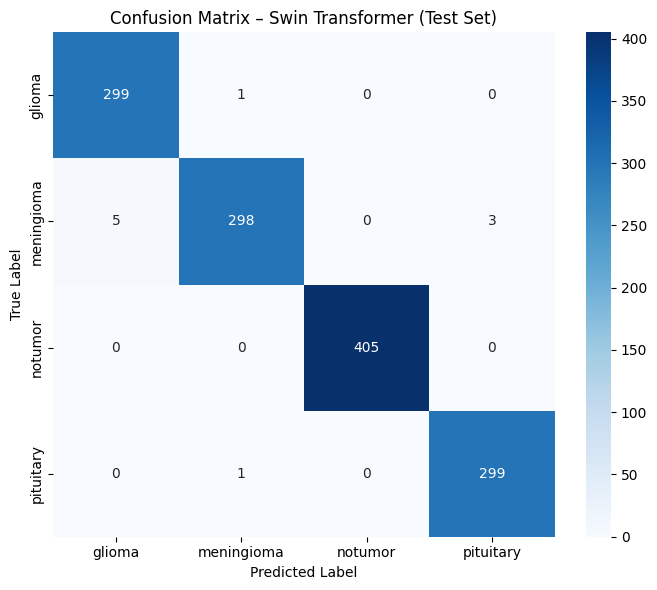

In [4]:
# ======================================
# FINAL EVALUATION CELL (TEST SET)
# ======================================
import timm
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# --------------------
# CONFIG
# --------------------
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MODEL_PATH = "saved_models/swin_final.pth"
model = timm.create_model(
    "swin_tiny_patch4_window7_224",
    pretrained=True,
    num_classes=NUM_CLASSES
).to(DEVICE)
class_names = ["glioma", "meningioma", "notumor", "pituitary"]

model.eval()

# --------------------
# LOAD MODEL SAFELY
# --------------------
state_dict = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)
model.load_state_dict(state_dict)

# --------------------
# EVALUATION
# --------------------
all_preds = []
all_labels = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(DEVICE)
        labels = labels.to(DEVICE)

        outputs = model(imgs)
        preds = outputs.argmax(dim=1)

        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

# --------------------
# METRICS
# --------------------
test_acc = accuracy_score(all_labels, all_preds) * 100
print(f"\n✅ FINAL TEST ACCURACY: {test_acc:.2f}%\n")

print("📊 CLASSIFICATION REPORT\n")
print(classification_report(
    all_labels,
    all_preds,
    target_names=class_names,
    digits=2
))

# --------------------
# CONFUSION MATRIX
# --------------------
cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(7,6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix – Swin Transformer (Test Set)")
plt.tight_layout()
plt.show()


## 5. Grad-CAM explainability
Visualizes which regions of the MRI drove the prediction. See `gradcam.py` for the script used to produce the images in the README.

Grad-CAM image: data\Testing\pituitary\Te-pi_0114.jpg
True label: pituitary


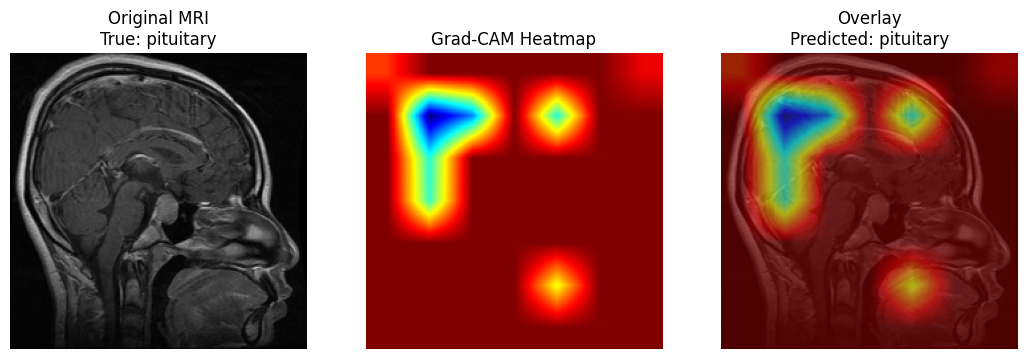

In [5]:
# ================================
# GRAD-CAM FOR TRAINED SWIN MODEL (RANDOM TEST IMAGE)
# ================================

import torch
import torch.nn.functional as F
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

# --------------------
# SETTINGS
# --------------------
TARGET_CLASS = None        # None = use model prediction
SAMPLE_INDEX = random.randint(0, len(test_ds.samples) - 1)  # random test image

# --------------------
# NORMALIZATION (FROM YOUR PREPROCESSING)
# --------------------
mean = np.array([0.5, 0.5, 0.5])
std  = np.array([0.5, 0.5, 0.5])
state_dict = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)
model.load_state_dict(state_dict)
model.eval()

# --------------------
# HOOK STORAGE
# --------------------
activations = None
gradients = None

def forward_hook(module, input, output):
    global activations
    activations = output

def backward_hook(module, grad_input, grad_output):
    global gradients
    gradients = grad_output[0]

# --------------------
# REGISTER HOOK (LAST SWIN BLOCK)
# --------------------
target_layer = model.layers[-1].blocks[-1].norm2
target_layer.register_forward_hook(forward_hook)
target_layer.register_backward_hook(backward_hook)

# --------------------
# LOAD IMAGE SAFELY FROM DATASET
# --------------------
IMG_PATH, true_label = test_ds.samples[SAMPLE_INDEX]
print("Grad-CAM image:", IMG_PATH)
print("True label:", test_ds.classes[true_label])

img = cv2.imread(IMG_PATH)
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))

# --------------------
# PREPROCESS (MATCH TRAINING)
# --------------------
img_norm = img / 255.0
img_norm = (img_norm - mean) / std

input_tensor = (
    torch.tensor(img_norm)
    .permute(2, 0, 1)
    .unsqueeze(0)
    .float()
    .to(DEVICE)
)

# --------------------
# FORWARD PASS
# --------------------
output = model(input_tensor)

pred_class = output.argmax(dim=1).item()
pred_name = test_ds.classes[pred_class]

if TARGET_CLASS is None:
    TARGET_CLASS = pred_class

score = output[0, TARGET_CLASS]

# --------------------
# BACKWARD PASS
# --------------------
model.zero_grad()
score.backward()

# --------------------
# TOKEN → FEATURE MAP (SWIN)
# --------------------
# activations: (B, N, C)
B, N, C = activations.shape
H = W = int(np.sqrt(N))

activations = activations.reshape(B, H, W, C).permute(0, 3, 1, 2)
gradients   = gradients.reshape(B, H, W, C).permute(0, 3, 1, 2)

# --------------------
# GRAD-CAM COMPUTATION
# --------------------
weights = gradients.mean(dim=(2, 3), keepdim=True)
cam = (weights * activations).sum(dim=1)

cam = F.relu(cam)
cam -= cam.min()
cam /= cam.max()

cam = cam.squeeze().detach().cpu().numpy()
cam = cv2.resize(cam, (IMG_SIZE, IMG_SIZE))

# --------------------
# HEATMAP & OVERLAY
# --------------------
heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
overlay = np.uint8(0.6 * heatmap + 0.4 * img)

# --------------------
# VISUALIZATION
# --------------------
plt.figure(figsize=(13, 4))

plt.subplot(1, 3, 1)
plt.title(f"Original MRI\nTrue: {test_ds.classes[true_label]}")
plt.imshow(img)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.title("Grad-CAM Heatmap")
plt.imshow(heatmap)
plt.axis("off")

plt.subplot(1, 3, 3)
plt.title(f"Overlay\nPredicted: {pred_name}")
plt.imshow(overlay)
plt.axis("off")

plt.show()
